In [37]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score

In [46]:
df=pd.read_csv(r"C:\Users\ADMIN\Downloads\customers (2).csv")

In [47]:
df

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [49]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [50]:
df["Channel"].value_counts()

Channel
1    298
2    142
Name: count, dtype: int64

In [51]:
x=df.drop("Channel",axis=1)
x

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,3,12669,9656,7561,214,2674,1338
1,3,7057,9810,9568,1762,3293,1776
2,3,6353,8808,7684,2405,3516,7844
3,3,13265,1196,4221,6404,507,1788
4,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...
435,3,29703,12051,16027,13135,182,2204
436,3,39228,1431,764,4510,93,2346
437,3,14531,15488,30243,437,14841,1867
438,3,10290,1981,2232,1038,168,2125


In [52]:
y=df["Channel"]
y

0      2
1      2
2      2
3      1
4      2
      ..
435    1
436    1
437    2
438    1
439    1
Name: Channel, Length: 440, dtype: int64

In [53]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.80,random_state=42,stratify=y)

In [54]:
sm=SMOTE(random_state=42)

In [55]:
x_train.value_counts()


Region  Fresh  Milk   Grocery  Frozen  Detergents_Paper  Delicatessen
1       18     7504   15205    1285    4797              6372            1
        514    8323   6869     529     93                1040            1
3       9413   8259   5126     666     1795              1451            1
        9396   11601  15775    2896    7677              1295            1
        9203   3373   2707     1286    1082              526             1
                                                                        ..
        491    10473  11532    744     5611              224             1
        403    254    610      774     54                63              1
        381    4025   9670     388     7271              1371            1
        355    7704   14682    398     8077              303             1
        76237  3473   7102     16538   778               918             1
Name: count, Length: 352, dtype: int64

In [56]:
y_train.value_counts()

Channel
1    238
2    114
Name: count, dtype: int64

In [57]:
x_train,y_train=sm.fit_resample(x_train,y_train)

In [58]:
x_train.value_counts()

Region  Fresh  Milk   Grocery  Frozen  Detergents_Paper  Delicatessen
1       18     7504   15205    1285    4797              6372            1
3       7124   9603   9581     1733    3210              1776            1
        7842   6046   8552     1691    3540              1874            1
        7823   6245   6544     4154    4074              964             1
        7780   2495   9464     669     2518              501             1
                                                                        ..
        3      2920   6252     440     223               709             1
2       32717  16784  13626    60869   1272              5609            1
        29635  2335   8280     3046    371               117             1
        27202  6965   11404    1948    4316              1687            1
3       76237  3473   7102     16538   778               918             1
Name: count, Length: 476, dtype: int64

In [59]:
y_train.value_counts()

Channel
1    238
2    238
Name: count, dtype: int64

In [60]:
model=RandomForestClassifier(max_leaf_nodes=20,n_estimators=100,random_state=42)

In [61]:
model.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,20
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [62]:
y_pred=model.predict(x_test)

In [63]:
y_pred

array([2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 1, 2, 2, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2,
       1, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1])

In [64]:
accuracy_score(y_pred,y_test)

0.9431818181818182

In [65]:
cn=confusion_matrix(y_pred,y_test)
cn

array([[57,  2],
       [ 3, 26]])

In [66]:
import seaborn as sns 
import matplotlib.pyplot as plt

<Axes: >

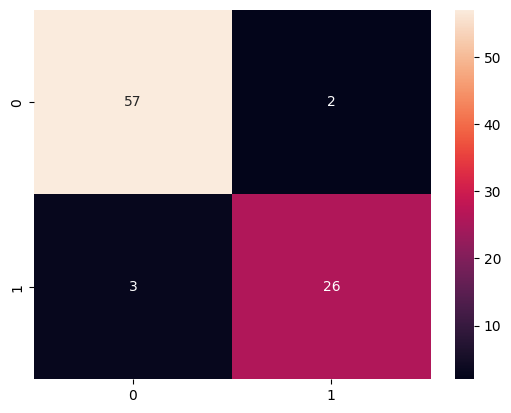

In [67]:
sns.heatmap(cn,annot=True)

In [68]:
cl=classification_report(y_pred,y_test)
cl

'              precision    recall  f1-score   support\n\n           1       0.95      0.97      0.96        59\n           2       0.93      0.90      0.91        29\n\n    accuracy                           0.94        88\n   macro avg       0.94      0.93      0.94        88\nweighted avg       0.94      0.94      0.94        88\n'

In [69]:
model1=RandomForestRegressor(random_state=42,n_estimators=100,max_leaf_nodes=20)

In [70]:
model1.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,20
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [74]:
y_pred1 = model1.predict(x_test)
y_pre1

array([1.83804117, 1.99622234, 1.90733685, 1.97645406, 1.0454892 ,
       1.99622234, 1.96793701, 1.16877881, 1.14564508, 1.00268244,
       1.99607949, 1.00299043, 1.00268244, 1.8429424 , 1.01700686,
       1.99622234, 1.00268244, 1.00252962, 1.0323501 , 1.01268244,
       1.00268244, 1.00268244, 1.14256404, 1.00268244, 1.00268244,
       1.00268244, 1.01268244, 1.22584707, 1.99622234, 1.97645223,
       1.19127586, 1.8563387 , 1.92693724, 1.00268244, 1.01268244,
       1.02222974, 1.98645406, 1.00268244, 1.05177841, 1.99622234,
       1.00268244, 1.06218881, 1.01262327, 1.99622234, 1.00268244,
       1.02579992, 1.98622234, 1.00268244, 1.00268244, 1.01496315,
       1.00268244, 1.57930458, 1.88615177, 1.00268244, 1.00268244,
       1.00268244, 1.99622234, 1.00268244, 1.91691273, 1.00303993,
       1.97669195, 1.26117382, 1.99622234, 1.00268244, 1.76094969,
       1.00268244, 1.00268244, 1.00268244, 1.01268244, 1.01303993,
       1.17571174, 1.00268244, 1.00268244, 1.00268244, 1.99622

In [75]:
print(y_test[:10])
print(y_pred[:10])

281    2
426    1
6      2
82     2
103    1
61     2
268    2
254    1
403    1
113    1
Name: Channel, dtype: int64
[1.83804117 1.99622234 1.90733685 1.97645406 1.0454892  1.99622234
 1.96793701 1.16877881 1.14564508 1.00268244]
